# 04 — Nouvelles variables : ratios et historique de crédit

**Objectif** : mesurer ce qu'apportent les 17 variables créées par `src/prepare_data.py`, à la régression logistique et à XGBoost :
- **4 ratios** entre les montants de la demande (crédit, annuité, revenu, prix du bien) ;
- **13 agrégats de `bureau.csv`** : les crédits du client chez d'autres organismes, résumés en une ligne par client.

Questions traitées :
1. Que valent ces variables seules, et quel est leur lien avec le défaut ?
2. Pourquoi un ratio mis en logarithme n'apporte-t-il rien à la régression logistique ?
3. Comment aider la régression logistique à capter un lien qui monte et descend ?
4. Combien gagne XGBoost, qui capte ces formes tout seul ?

**Règles suivies** : mêmes 5 plis et mêmes réglages qu'aux notebooks 02 et 03 ; seules les variables changent.
Les nouvelles variables sont calculées client par client, sans utiliser `TARGET`, donc sans fuite d'information.
Le jeu de test n'est toujours pas chargé.

*Durée d'exécution : environ 10 minutes sur 8 cœurs, dont 4 pour XGBoost.*

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, PercentFormatter
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, KBinsDiscretizer, OneHotEncoder, OrdinalEncoder, StandardScaler

sys.path.insert(0, "..")  # pour importer src/
from src.prepare_data import COLONNES_HORS_MODELE, VARIABLES_BUREAU, VARIABLES_NOUVELLES, VARIABLES_RATIOS

BLEU, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRIS = "#8a8984"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e8e7e2",
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2,
})
DEBUT_NOTEBOOK = time.perf_counter()

## 1. Données, plis et résultats des notebooks 02 et 03

In [2]:
DOSSIER_PROCESSED = Path("..") / "data" / "processed"
train = pd.read_parquet(DOSSIER_PROCESSED / "train.parquet")
y = train["TARGET"].to_numpy()
TAUX_MOYEN = y.mean()

VARIABLES_BASE = [c for c in train.columns if c not in COLONNES_HORS_MODELE + VARIABLES_NOUVELLES]
TOUTES_VARIABLES = VARIABLES_BASE + VARIABLES_NOUVELLES
CATEGORIELLES = [c for c in VARIABLES_BASE if not pd.api.types.is_numeric_dtype(train[c])]
print(f"{len(train):,} prêts ; {len(VARIABLES_BASE)} variables de base + {len(VARIABLES_NOUVELLES)} nouvelles "
      f"({len(VARIABLES_RATIOS)} ratios, {len(VARIABLES_BUREAU)} agrégats de bureau.csv) = {len(TOUTES_VARIABLES)}")

PLIS = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)  # les mêmes plis qu'aux notebooks 02 et 03
INDICES_PLIS = [validation for _, validation in PLIS.split(train, y)]
resultats = []


def evaluer(nom, score, nb_variables):
    """ROC AUC et PR AUC sur chacun des 5 plis (score : plus il est élevé, plus le risque est grand)."""
    roc = [roc_auc_score(y[i], score[i]) for i in INDICES_PLIS]
    pr = [average_precision_score(y[i], score[i]) for i in INDICES_PLIS]
    resultats.append({"modele": nom, "variables": nb_variables, "roc_auc": np.mean(roc),
                      "ecart_type": np.std(roc), "pr_auc": np.mean(pr), "auc_par_pli": roc})
    print(f"{nom} : ROC AUC {np.mean(roc):.4f} ± {np.std(roc):.4f}, PR AUC {np.mean(pr):.3f}")


# Prédictions out-of-fold des notebooks 02 et 03, sur les mêmes clients dans le même ordre
oof_02 = pd.read_parquet(DOSSIER_PROCESSED / "oof_02.parquet")
oof_03 = pd.read_parquet(DOSSIER_PROCESSED / "oof_03.parquet")
for precedent in (oof_02, oof_03):
    assert (precedent["SK_ID_CURR"].to_numpy() == train["SK_ID_CURR"].to_numpy()).all()
NOM_LOGISTIQUE_82 = "Logistique, 82 variables (notebook 02)"
NOM_XGB_82 = "XGBoost, 82 variables (notebook 03)"
evaluer(NOM_LOGISTIQUE_82, oof_02["logistique_complete"].to_numpy(), len(VARIABLES_BASE))
evaluer(NOM_XGB_82, oof_03["xgboost"].to_numpy(), len(VARIABLES_BASE))

246,008 prêts ; 82 variables de base + 17 nouvelles (4 ratios, 13 agrégats de bureau.csv) = 99


Logistique, 82 variables (notebook 02) : ROC AUC 0.7471 ± 0.0024, PR AUC 0.227


XGBoost, 82 variables (notebook 03) : ROC AUC 0.7564 ± 0.0016, PR AUC 0.240


## 2. Les 17 nouvelles variables

L'**AUC seule** d'une variable mesure à quel point elle classe bien les clients à elle seule (0,5 = pas mieux que le hasard).
Elle est orientée : si le risque baisse quand la variable augmente, on retourne le classement. Repères : `EXT_SOURCE_3` atteint 0,68 et l'âge 0,58.
Elle est calculée sur les clients qui ont une valeur.

In [3]:
DEFINITIONS = {
    "RATIO_CREDIT_REVENU": "montant du crédit / revenu du client",
    "RATIO_ANNUITE_REVENU": "annuité / revenu : part du revenu consacrée au remboursement (taux d'effort)",
    "RATIO_CREDIT_ANNUITE": "crédit / annuité : nombre d'annuités pour rembourser le capital (dépend de la durée et du taux)",
    "RATIO_BIEN_CREDIT": "prix du bien / crédit (en dessous de 1 : le crédit dépasse le prix du bien)",
    "BUREAU_AUCUN_HISTORIQUE": "1 si le client n'a aucun crédit déclaré chez d'autres organismes",
    "BUREAU_NB_CREDITS": "nombre de crédits chez d'autres organismes",
    "BUREAU_NB_ACTIFS": "dont crédits en cours",
    "BUREAU_NB_RECENTS": "dont crédits demandés dans l'année précédant la demande",
    "BUREAU_NB_VENDUS_OU_IRRECOUVRABLES": "dont crédits revendus ou passés en perte",
    "BUREAU_NB_EN_RETARD": "dont crédits en retard de paiement au moment de la demande",
    "BUREAU_RETARD_MAX_JOURS": "plus long retard en cours au moment de la demande (jours)",
    "BUREAU_MONTANT_RETARD_MAX": "plus gros montant impayé atteint jusqu'ici sur un crédit",
    "BUREAU_NB_PROLONGATIONS": "nombre de prolongations de crédit",
    "BUREAU_DETTE_EN_COURS": "dette restante sur les crédits en cours",
    "BUREAU_RATIO_DETTE_REVENU": "dette en cours / revenu",
    "BUREAU_ANNEES_DEPUIS_DERNIER": "ancienneté du crédit le plus récent (années)",
    "BUREAU_ANNEES_DEPUIS_PREMIER": "ancienneté du crédit le plus ancien (années, 8 ans au plus dans les données)",
}
assert list(DEFINITIONS) == VARIABLES_NOUVELLES


def auc_seule(colonne):
    """AUC d'une variable utilisée seule comme score, et sens dans lequel elle joue."""
    renseigne = train[colonne].notna().to_numpy()
    auc = roc_auc_score(y[renseigne], train.loc[renseigne, colonne])
    return max(auc, 1 - auc), "augmente" if auc > 0.5 else "diminue"


tableau = []
for colonne, definition in DEFINITIONS.items():
    auc, sens = auc_seule(colonne)
    tableau.append({"variable": colonne, "définition": definition, "manquantes": train[colonne].isna().mean(),
                    "médiane": train[colonne].median(), "AUC seule": auc, "le risque monte quand elle": sens})
tableau = pd.DataFrame(tableau).set_index("variable")
(tableau.style.format({"manquantes": "{:.1%}", "médiane": "{:,.2f}", "AUC seule": "{:.3f}"})
 .background_gradient(subset=["AUC seule"], cmap="Blues", vmin=0.5, vmax=0.62))

,définition,manquantes,médiane,AUC seule,le risque monte quand elle
variable,,,,,
RATIO_CREDIT_REVENU,montant du crédit / revenu du client,0.0%,3.27,0.502,diminue
RATIO_ANNUITE_REVENU,annuité / revenu : part du revenu consacrée au remboursement (taux d'effort),0.0%,0.16,0.521,augmente
RATIO_CREDIT_ANNUITE,crédit / annuité : nombre d'annuités pour rembourser le capital (dépend de la durée et du taux),0.0%,20.00,0.533,diminue
RATIO_BIEN_CREDIT,prix du bien / crédit (en dessous de 1 : le crédit dépasse le prix du bien),0.1%,0.89,0.568,diminue
BUREAU_AUCUN_HISTORIQUE,1 si le client n'a aucun crédit déclaré chez d'autres organismes,0.0%,0.00,0.520,augmente
BUREAU_NB_CREDITS,nombre de crédits chez d'autres organismes,0.0%,4.00,0.523,diminue
BUREAU_NB_ACTIFS,dont crédits en cours,0.0%,1.00,0.529,augmente
BUREAU_NB_RECENTS,dont crédits demandés dans l'année précédant la demande,0.0%,0.00,0.552,augmente
BUREAU_NB_VENDUS_OU_IRRECOUVRABLES,dont crédits revendus ou passés en perte,0.0%,0.00,0.502,augmente


- **Prises seules, les nouvelles variables sont faibles.** Les meilleures, l'ancienneté du dernier et du premier crédit chez un autre organisme
  (0,582 et 0,577), font jeu égal avec l'âge, loin d'`EXT_SOURCE_3` (0,68).
- **Le sens des effets est logique** : le risque monte avec les crédits récents, la dette en cours et l'absence d'historique,
  et baisse avec l'ancienneté des crédits.
- **Une AUC seule proche de 0,5 ne veut pas dire « inutile »**. L'AUC ne mesure qu'un classement dans un seul sens : une variable dont le lien
  monte puis descend obtient une AUC faible. C'est le cas de `RATIO_CREDIT_ANNUITE` (0,533), qui va se révéler la plus utile des 17.
- Le rapport crédit / revenu, critère intuitif d'un banquier, ne classe presque pas les clients à lui seul (0,502).

## 3. Lien avec le défaut

### 3.1 `RATIO_CREDIT_ANNUITE` : un lien en dents de scie

On découpe les prêts en 50 tranches de même effectif selon le ratio, et on calcule le taux de défaut de chaque tranche.

Crédits renouvelables : 9.5% des prêts, dont 99.9% avec un ratio d'exactement 20 ; prêts classiques avec un ratio de 20 : 3


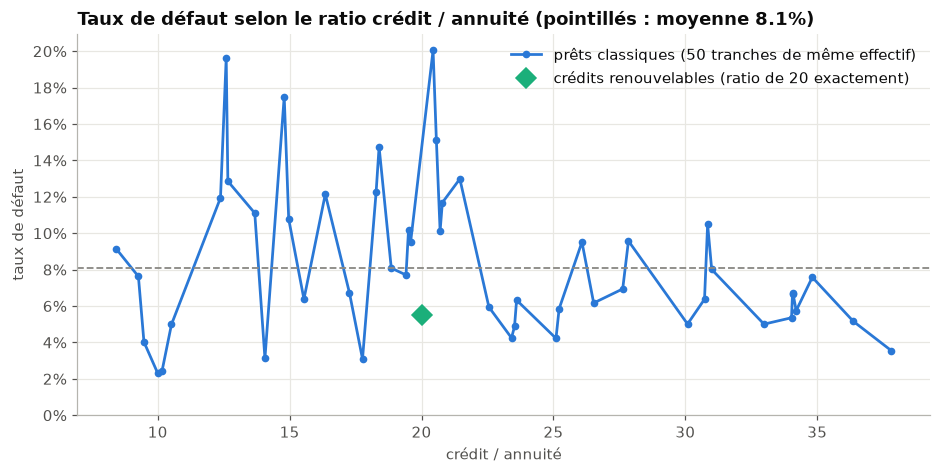

In [4]:
renouvelables = train["NAME_CONTRACT_TYPE"] == "Revolving loans"
ratio = train["RATIO_CREDIT_ANNUITE"]
exactement_20 = ratio.round(6) == 20
print(f"Crédits renouvelables : {renouvelables.mean():.1%} des prêts, dont {exactement_20[renouvelables].mean():.1%} "
      f"avec un ratio d'exactement 20 ; prêts classiques avec un ratio de 20 : {exactement_20[~renouvelables].sum()}")


def taux_par_tranche(valeurs, cibles, nb_tranches):
    """Taux de défaut par tranches de même effectif, placé à la valeur médiane de chaque tranche."""
    tranches = pd.qcut(valeurs, nb_tranches, duplicates="drop")
    return pd.DataFrame({"valeur": valeurs, "defaut": cibles}).groupby(tranches, observed=True).agg(
        mediane=("valeur", "median"), taux=("defaut", "mean"), prets=("defaut", "size"))


classiques = taux_par_tranche(ratio[~renouvelables], y[~renouvelables.to_numpy()], 50)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(classiques["mediane"], classiques["taux"], color=BLEU, marker="o", markersize=4, linewidth=1.8,
        label="prêts classiques (50 tranches de même effectif)")
ax.plot([20], [y[renouvelables.to_numpy()].mean()], color=AQUA, marker="D", markersize=9, linestyle="none",
        label="crédits renouvelables (ratio de 20 exactement)")
ax.axhline(TAUX_MOYEN, color=GRIS, linestyle="--", linewidth=1.2)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_locator(MultipleLocator(0.02))
ax.set_ylim(0, None)
ax.set_xlabel("crédit / annuité")
ax.set_ylabel("taux de défaut")
ax.set_title(f"Taux de défaut selon le ratio crédit / annuité (pointillés : moyenne {TAUX_MOYEN:.1%})", loc="left")
ax.legend(frameon=False, loc="upper right")
plt.show()

Les valeurs exactes du ratio reviennent très souvent. Les 10 plus fréquentes chez les prêts classiques :

In [5]:
arrondi = ratio[~renouvelables].round(3)
frequentes = (pd.DataFrame({"ratio": arrondi, "defaut": y[~renouvelables.to_numpy()]})
              .groupby("ratio").agg(prets=("defaut", "size"), taux_de_defaut=("defaut", "mean"))
              .sort_values("prets", ascending=False).head(10))
print(f"{arrondi.nunique():,} valeurs distinctes ; les 50 plus fréquentes couvrent "
      f"{arrondi.value_counts().head(50).sum() / len(arrondi):.0%} des prêts classiques")
frequentes.style.format({"prets": "{:,.0f}", "taux_de_defaut": "{:.1%}"}).background_gradient(
    subset=["taux_de_defaut"], cmap="Oranges", vmin=0, vmax=0.25)

11,210 valeurs distinctes ; les 50 plus fréquentes couvrent 15% des prêts classiques


,prets,taux_de_defaut
ratio,,
34.200000,"1,877",5.0%
34.083000,"1,388",7.2%
30.844000,"1,161",10.0%
19.585000,"1,089",9.3%
34.063000,"1,033",8.3%
34.203000,"1,016",5.0%
20.713000,980,9.3%
23.603000,970,5.4%
20.459000,966,20.3%


- **Les crédits renouvelables ont tous un ratio de 20** (99,9 % d'entre eux) : leur annuité est fixée à 5 % du montant.
  Ils font 5,5 % de défauts, moins que la moyenne.
- **Pour les prêts classiques, le lien est en dents de scie.** Deux tranches voisines peuvent avoir des risques très différents :
  2,3 % de défauts autour de 10,0, mais 19,6 % autour de 12,6 ; 20,1 % autour de 20,4, mais 4,2 % autour de 23,4.
- **Certaines valeurs exactes reviennent des centaines de fois**, avec des taux de défaut très différents : 34,200 (1 877 prêts, 5,0 %)
  contre 20,459 (966 prêts, 20,3 %).

**Une explication probable : une grille tarifaire.** Pour un prêt remboursé en $n$ échéances au taux $r$ par échéance,
le ratio vaut $\frac{1 - (1 + r)^{-n}}{r}$. À durée égale, plus le taux est élevé, plus le ratio est petit : pour 24 échéances,
il vaut 24 sans intérêts, 18,9 à 2 % par échéance et 16,9 à 3 %. Les valeurs exactes qui reviennent souvent correspondraient alors
aux couples (durée, taux) proposés par Home Credit. C'est une hypothèse : la durée du prêt ne figure pas dans `application_train.csv`.

**Conséquence à garder en tête** : si Home Credit fixe le taux selon le risque qu'il perçoit, ce ratio transmet au modèle une partie
de l'évaluation déjà faite par le prêteur. C'est légitime si le taux est connu au moment de la décision, mais le modèle ne repart pas de zéro.

### 3.2 Trois autres variables

Le prix du bien rapporté au crédit, l'ancienneté du dernier crédit chez un autre organisme et le nombre de crédits demandés dans l'année :

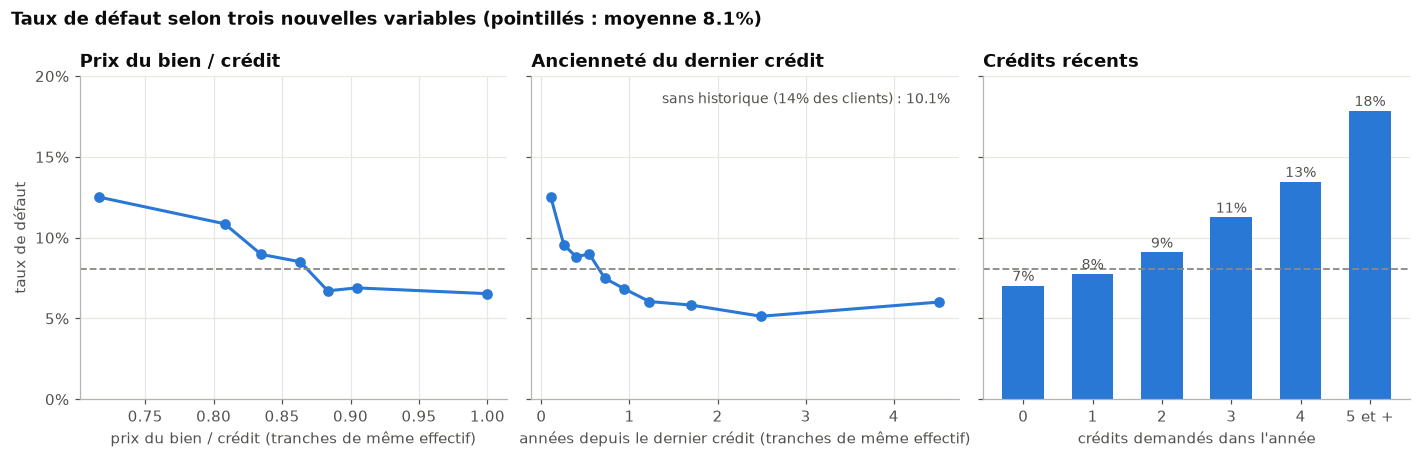

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)

# Les 0,1 % de prêts au-dessus de 1 sont regroupés avec 1, pour ne pas étirer l'axe
bien = taux_par_tranche(train["RATIO_BIEN_CREDIT"].clip(upper=1), y, 10)
axes[0].plot(bien["mediane"], bien["taux"], color=BLEU, marker="o", markersize=6)
axes[0].set_xlabel("prix du bien / crédit (tranches de même effectif)")
axes[0].set_title("Prix du bien / crédit", loc="left")

renseigne = train["BUREAU_ANNEES_DEPUIS_DERNIER"].notna().to_numpy()
dernier = taux_par_tranche(train.loc[renseigne, "BUREAU_ANNEES_DEPUIS_DERNIER"], y[renseigne], 10)
axes[1].plot(dernier["mediane"], dernier["taux"], color=BLEU, marker="o", markersize=6)
axes[1].text(0.98, 0.95, f"sans historique ({1 - renseigne.mean():.0%} des clients) : {y[~renseigne].mean():.1%}",
             transform=axes[1].transAxes, ha="right", va="top", fontsize=9, color="#52514e")
axes[1].set_xlabel("années depuis le dernier crédit (tranches de même effectif)")
axes[1].set_title("Ancienneté du dernier crédit", loc="left")

recents = pd.Series(y).groupby(train["BUREAU_NB_RECENTS"].clip(upper=5).to_numpy()).mean()
axes[2].bar(range(len(recents)), recents, color=BLEU, width=0.6)
for position, taux in enumerate(recents):
    axes[2].text(position, taux + 0.003, f"{taux:.0%}", ha="center", fontsize=9, color="#52514e")
axes[2].set_xticks(range(len(recents)), ["0", "1", "2", "3", "4", "5 et +"])
axes[2].set_xlabel("crédits demandés dans l'année")
axes[2].set_title("Crédits récents", loc="left")
axes[2].grid(axis="x", visible=False)

for ax in axes:
    ax.axhline(TAUX_MOYEN, color=GRIS, linestyle="--", linewidth=1.2)
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
axes[0].yaxis.set_major_locator(MultipleLocator(0.05))
axes[0].set_ylim(0, 0.2)
axes[0].set_ylabel("taux de défaut")
fig.suptitle(f"Taux de défaut selon trois nouvelles variables (pointillés : moyenne {TAUX_MOYEN:.1%})",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

- **Prix du bien / crédit** : quand le crédit dépasse nettement le prix du bien (ratio sous 0,78), le taux de défaut atteint 12,5 %,
  contre 6,5 % quand le crédit couvre à peu près le prix du bien (ratio entre 0,93 et 1, soit 40 % des prêts).
- **Ancienneté du dernier crédit** : un client qui vient d'emprunter ailleurs (dans les deux mois environ) fait défaut à 12,5 %,
  contre 5 à 6 % quand son dernier crédit date de plus de deux ans. **Ne pas avoir d'historique** est aussi un signal (10,1 %) :
  le prêteur ne sait rien du comportement passé du client.
- **Crédits demandés dans l'année** : le risque monte régulièrement, de 7 % sans aucune demande à 18 % pour cinq demandes ou plus.
  Multiplier les demandes de crédit signale souvent un besoin d'argent pressant.

## 4. Régression logistique

### 4.1 Ajouter les variables une famille à la fois

Même pipeline qu'au notebook 02 (médiane et indicateur de valeur manquante, standardisation, one-hot, $C = 0{,}1$), avec un ajout :
les **comptes et montants de `bureau.csv`** (nombre de crédits, retards, dettes) sont positifs, souvent nuls, avec des valeurs extrêmes
(une dette de 334 millions). On les passe par $\log(1 + x)$, qui garde le 0 à 0 et écrase les valeurs extrêmes, avant de les standardiser.

**Un ratio en logarithme n'apporte rien à la logistique.** Le modèle contient déjà le logarithme de chaque montant, avec un coefficient libre :

$$\log\left(\frac{\text{crédit}}{\text{revenu}}\right) = \log(\text{crédit}) - \log(\text{revenu})$$

Le ratio en logarithme n'est qu'une combinaison de colonnes déjà présentes : le modèle pouvait déjà l'écrire.
Les ratios **bruts**, en revanche, ne sont pas des combinaisons linéaires de ces logarithmes. On teste les deux versions.

In [7]:
MONTANTS = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]
# Comptes et montants de bureau.csv : positifs, souvent nuls, avec des valeurs extrêmes
BUREAU_ASYMETRIQUES = ["BUREAU_NB_CREDITS", "BUREAU_NB_ACTIFS", "BUREAU_NB_RECENTS", "BUREAU_NB_VENDUS_OU_IRRECOUVRABLES",
                       "BUREAU_NB_EN_RETARD", "BUREAU_RETARD_MAX_JOURS", "BUREAU_MONTANT_RETARD_MAX",
                       "BUREAU_NB_PROLONGATIONS", "BUREAU_DETTE_EN_COURS", "BUREAU_RATIO_DETTE_REVENU"]


def regression_logistique(variables, ratios_en_log=False, intervalles=0, C=0.1):
    categorielles = [c for c in variables if c in CATEGORIELLES]
    en_log = MONTANTS + ([c for c in VARIABLES_RATIOS if c in variables] if ratios_en_log else [])
    en_log_plus_un = [c for c in BUREAU_ASYMETRIQUES if c in variables]
    autres = [c for c in variables if c not in categorielles + en_log + en_log_plus_un]
    etapes = [
        ("logarithme", make_pipeline(SimpleImputer(strategy="median"),
                                     FunctionTransformer(np.log, feature_names_out="one-to-one"), StandardScaler()), en_log),
        ("logarithme_plus_un", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                             StandardScaler()), en_log_plus_un),
        ("numeriques", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), autres),
        ("categorielles", make_pipeline(SimpleImputer(strategy="constant", fill_value="non renseigné"),
                                        OneHotEncoder(min_frequency=100, handle_unknown="infrequent_if_exist",
                                                      drop="if_binary", sparse_output=False)), categorielles),
    ]
    if intervalles:
        # Section 4.2 : une colonne 0/1 par tranche du ratio crédit / annuité, en plus du ratio lui-même
        etapes.append(("intervalles_duree", make_pipeline(
            SimpleImputer(strategy="median"),
            KBinsDiscretizer(n_bins=intervalles, encode="onehot-dense", strategy="quantile",
                             quantile_method="averaged_inverted_cdf")), ["RATIO_CREDIT_ANNUITE"]))
    return make_pipeline(ColumnTransformer(etapes, verbose_feature_names_out=False), LogisticRegression(C=C, max_iter=2000))


def logistique_oof(variables, **options):
    """Probabilité de défaut out-of-fold : chaque client est prédit par le modèle qui ne l'a pas vu."""
    return cross_val_predict(regression_logistique(variables, **options), train[variables], y,
                             cv=PLIS, method="predict_proba", n_jobs=5)[:, 1]


debut = time.perf_counter()
evaluer("Logistique + 4 ratios en logarithme",
        logistique_oof(VARIABLES_BASE + VARIABLES_RATIOS, ratios_en_log=True), len(VARIABLES_BASE) + 4)
evaluer("Logistique + 4 ratios bruts", logistique_oof(VARIABLES_BASE + VARIABLES_RATIOS), len(VARIABLES_BASE) + 4)
evaluer("Logistique + 13 variables de bureau.csv", logistique_oof(VARIABLES_BASE + VARIABLES_BUREAU), len(VARIABLES_BASE) + 13)
NOM_LOGISTIQUE_99 = "Logistique, 99 variables"
oof_logistique_99 = logistique_oof(TOUTES_VARIABLES)
evaluer(NOM_LOGISTIQUE_99, oof_logistique_99, len(TOUTES_VARIABLES))
print(f"Durée : {time.perf_counter() - debut:.0f} s")

Logistique + 4 ratios en logarithme : ROC AUC 0.7473 ± 0.0025, PR AUC 0.227


Logistique + 4 ratios bruts : ROC AUC 0.7484 ± 0.0022, PR AUC 0.229


Logistique + 13 variables de bureau.csv : ROC AUC 0.7503 ± 0.0021, PR AUC 0.231


Logistique, 99 variables : ROC AUC 0.7516 ± 0.0019, PR AUC 0.233
Durée : 120 s


- **Les ratios en logarithme n'apportent rien** : 0,7473 contre 0,7471, comme prévu. La différence restante vient de la régularisation
  et de l'imputation des valeurs manquantes, pas d'une information nouvelle.
- **Les ratios bruts apportent un peu** (+0,0013) : ils ne sont pas des combinaisons linéaires des logarithmes.
- **L'historique de `bureau.csv` apporte plus** (+0,0032) : c'est une vraie information nouvelle, absente de la demande de prêt.
- **Avec les 99 variables : 0,7516** (+0,0045). Les deux gains s'additionnent presque exactement (0,0013 + 0,0032) :
  les ratios et l'historique de crédit apportent des informations différentes.
- Le gain reste modeste : la logistique ne peut pas exploiter les dents de scie de `RATIO_CREDIT_ANNUITE`.

### 4.2 Aider la logistique avec des intervalles

La logistique donne **un seul coefficient** au ratio crédit / annuité : le risque ne peut que monter ou descendre avec lui.
Pour lui laisser suivre les dents de scie, on découpe le ratio en tranches de même effectif et on crée une colonne 0/1 par tranche
(`KBinsDiscretizer`). Chaque tranche reçoit alors son propre coefficient. C'est la méthode des grilles de score bancaires classiques,
qui découpent les variables en classes.

Les bornes des tranches sont calculées dans le pipeline, donc sur les seuls plis d'entraînement.
Le ratio vaut exactement 20 pour 9,5 % des prêts : plusieurs bornes tombent sur 20, et `KBinsDiscretizer` fusionne ces tranches vides
(d'où l'avertissement masqué ci-dessous et un nombre réel de tranches inférieur au nombre demandé).

In [8]:
warnings.filterwarnings("ignore", message="Bins whose width are too small")

debut = time.perf_counter()
choix_intervalles, oof_par_intervalles = [], {}
for nb_intervalles in [10, 30, 100, 200]:
    oof_par_intervalles[nb_intervalles] = logistique_oof(TOUTES_VARIABLES, intervalles=nb_intervalles)
    roc = [roc_auc_score(y[i], oof_par_intervalles[nb_intervalles][i]) for i in INDICES_PLIS]
    # Aperçu sur tout l'apprentissage, seulement pour compter les tranches réellement créées
    reelles = KBinsDiscretizer(n_bins=nb_intervalles, encode="ordinal", strategy="quantile",
                               quantile_method="averaged_inverted_cdf").fit(
        train[["RATIO_CREDIT_ANNUITE"]].fillna(ratio.median())).n_bins_[0]
    choix_intervalles.append({"tranches demandées": nb_intervalles, "tranches réelles": reelles,
                              "roc_auc": np.mean(roc), "ecart_type": np.std(roc)})
print(f"Durée : {time.perf_counter() - debut:.0f} s")
choix_intervalles = pd.DataFrame(choix_intervalles).set_index("tranches demandées")
choix_intervalles.style.format({"roc_auc": "{:.4f}", "ecart_type": "{:.4f}"})

Durée : 176 s


,tranches réelles,roc_auc,ecart_type
tranches demandées,,,
10,10,0.7557,0.0016
30,28,0.7568,0.0019
100,92,0.7626,0.0013
200,182,0.7630,0.0013


In [9]:
NB_INTERVALLES = 100
NOM_LOGISTIQUE_INTERVALLES = f"Logistique, 99 variables + {NB_INTERVALLES} tranches du ratio crédit / annuité"
oof_logistique_intervalles = oof_par_intervalles[NB_INTERVALLES]
evaluer(NOM_LOGISTIQUE_INTERVALLES, oof_logistique_intervalles, len(TOUTES_VARIABLES))

Logistique, 99 variables + 100 tranches du ratio crédit / annuité : ROC AUC 0.7626 ± 0.0013, PR AUC 0.247


- **Plus les tranches sont fines, meilleur est le modèle**, jusqu'à une centaine : 0,7557 avec 10 tranches, 0,7626 avec 100 (92 réelles),
  puis presque plus rien avec 200 (0,7630). Ce sont donc des **valeurs précises** du ratio qui comptent, pas une tendance générale,
  ce qui va dans le sens de l'hypothèse de la grille tarifaire.
- **Avec 100 tranches, la logistique atteint 0,7626**, soit +0,0155 par rapport au notebook 02. Elle dépasse le XGBoost du notebook 03
  (0,7564) : **une variable bien construite a rapporté plus que le changement d'algorithme**.
- **Le prix à payer** : 92 coefficients pour une seule variable, donc une grille moins lisible. Le risque de sur-apprentissage reste limité,
  car chaque tranche contient environ 2 000 prêts par pli d'entraînement et la régularisation ($C = 0{,}1$) freine les coefficients.
- On garde 100 tranches : 200 ne gagne que 0,0004 pour deux fois plus de colonnes.

## 5. XGBoost avec les 99 variables

Exactement les réglages du notebook 03 (profondeur 3, taux d'apprentissage 0,05, early stopping après 100 arbres sans progrès
sur 10 % des clients d'entraînement de chaque pli) : la seule différence avec le notebook 03 est l'ajout des 17 variables.

Un arbre n'a pas besoin d'intervalles : il découpe lui-même le ratio en tranches, aussi fines qu'il le faut.
En revanche, il a du mal à **construire** un ratio : avec des coupures du type « crédit < a » puis « revenu > b », il découpe le plan
(crédit, revenu) en rectangles, alors que « crédit / revenu > 3 » est une droite en diagonale. Il lui faudrait beaucoup de coupures
pour l'approcher en escalier. Lui donner le ratio tout fait peut donc l'aider davantage que la logistique.

L'importance est cette fois le **gain cumulé** (`total_gain`) : la baisse totale de la log-loss apportée par toutes les coupures
sur une variable, moyennée sur les 5 modèles des plis.

In [10]:
def preparation_arbres(variables):
    categorielles = [c for c in variables if c in CATEGORIELLES]
    numeriques = [c for c in variables if c not in categorielles]
    return ColumnTransformer([
        ("numeriques", "passthrough", numeriques),
        ("categorielles", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                         encoded_missing_value=-1, min_frequency=100), categorielles),
    ], verbose_feature_names_out=False).set_output(transform="pandas")  # garde les noms des variables


def xgboost(profondeur, taux_apprentissage, nb_arbres=5000):
    return xgb.XGBClassifier(
        n_estimators=nb_arbres, learning_rate=taux_apprentissage, max_depth=profondeur,
        subsample=0.8, colsample_bytree=0.6, min_child_weight=10, reg_lambda=1.0,
        tree_method="hist", eval_metric="auc", early_stopping_rounds=100, n_jobs=8, random_state=42)


def xgboost_oof(variables, profondeur=3, taux_apprentissage=0.05):
    """Validation croisée avec early stopping dans chaque pli.
    Renvoie les prédictions out-of-fold, le nombre d'arbres retenus par pli et l'importance moyenne des variables."""
    X = train[variables]
    oof, nb_arbres, importances = np.zeros(len(y)), [], []
    for entrainement, validation in PLIS.split(X, y):
        preparation = preparation_arbres(variables).fit(X.iloc[entrainement])
        X_entrainement = preparation.transform(X.iloc[entrainement])
        # 10 % des clients d'entraînement du pli servent à décider quand arrêter
        X_fit, X_arret, y_fit, y_arret = train_test_split(X_entrainement, y[entrainement], test_size=0.1,
                                                          stratify=y[entrainement], random_state=42)
        modele = xgboost(profondeur, taux_apprentissage).fit(X_fit, y_fit, eval_set=[(X_arret, y_arret)], verbose=False)
        oof[validation] = modele.predict_proba(preparation.transform(X.iloc[validation]))[:, 1]  # avec le meilleur nombre d'arbres
        nb_arbres.append(modele.best_iteration + 1)
        # Gain cumulé des seuls arbres retenus, en part du total du pli
        gain = pd.Series(modele.get_booster()[: modele.best_iteration + 1].get_score(importance_type="total_gain"))
        importances.append(gain / gain.sum())
    importance = pd.concat(importances, axis=1).reindex(variables).fillna(0).mean(axis=1)
    return oof, nb_arbres, importance.sort_values(ascending=False)


debut = time.perf_counter()
NOM_XGB_99 = "XGBoost, 99 variables"
oof_xgb_99, nb_arbres_xgb, importance_xgb = xgboost_oof(TOUTES_VARIABLES)
print(f"Durée : {time.perf_counter() - debut:.0f} s ; arbres retenus par pli : {nb_arbres_xgb}")
evaluer(NOM_XGB_99, oof_xgb_99, len(TOUTES_VARIABLES))

Durée : 234 s ; arbres retenus par pli : [1002, 1311, 872, 1065, 1144]
XGBoost, 99 variables : ROC AUC 0.7692 ± 0.0016, PR AUC 0.255


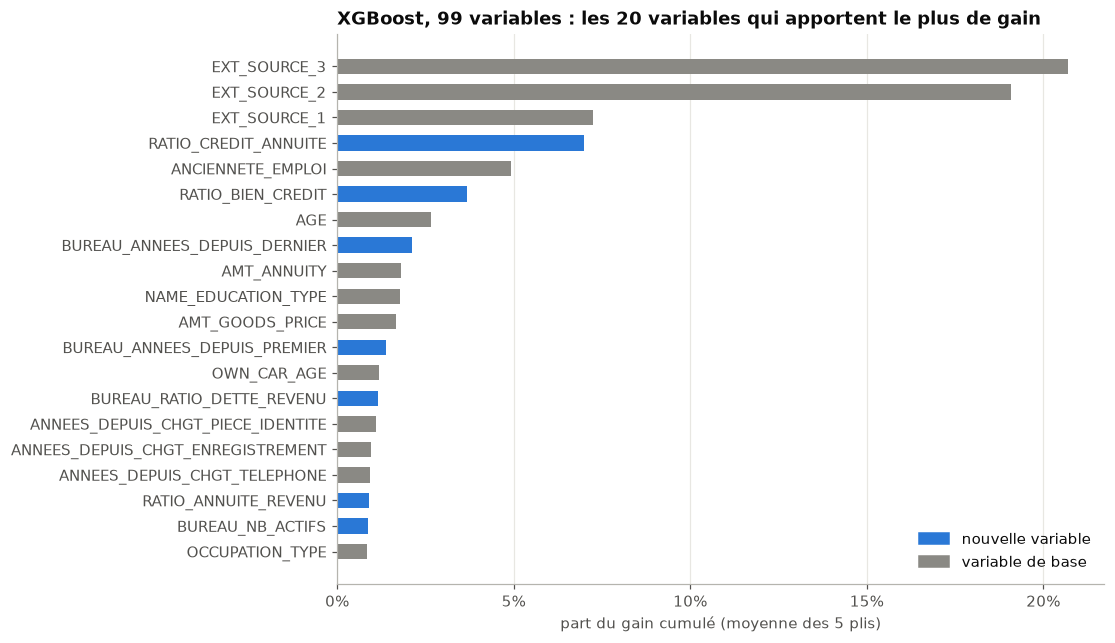

Part du gain cumulé : 47% pour les 3 scores externes, 21% pour les 17 nouvelles variables
FLAG_DOCUMENT_3 (5e au notebook 03 avec le gain moyen) : rang 38 avec le gain cumulé
Rang des nouvelles variables parmi les 99 : RATIO_CREDIT_ANNUITE (4), RATIO_BIEN_CREDIT (6), BUREAU_ANNEES_DEPUIS_DERNIER (8), BUREAU_ANNEES_DEPUIS_PREMIER (12), BUREAU_RATIO_DETTE_REVENU (14), RATIO_ANNUITE_REVENU (18), BUREAU_NB_ACTIFS (19), BUREAU_NB_CREDITS (22)


In [11]:
plus_importantes = importance_xgb.head(20).sort_values()
nouvelles = plus_importantes.index.isin(VARIABLES_NOUVELLES)

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(plus_importantes.index, plus_importantes, color=np.where(nouvelles, BLEU, GRIS), height=0.6)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.xaxis.set_major_locator(MultipleLocator(0.05))  # graduations rondes : pas de 2,5 % affiché « 2 % »
ax.set_xlabel("part du gain cumulé (moyenne des 5 plis)")
ax.set_title("XGBoost, 99 variables : les 20 variables qui apportent le plus de gain", loc="left")
ax.legend(handles=[Patch(color=BLEU, label="nouvelle variable"), Patch(color=GRIS, label="variable de base")],
          frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

rangs = importance_xgb.rank(ascending=False).astype(int)
print(f"Part du gain cumulé : {importance_xgb[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].sum():.0%} pour les 3 scores externes, "
      f"{importance_xgb[VARIABLES_NOUVELLES].sum():.0%} pour les 17 nouvelles variables")
print(f"FLAG_DOCUMENT_3 (5e au notebook 03 avec le gain moyen) : rang {rangs['FLAG_DOCUMENT_3']} avec le gain cumulé")
print("Rang des nouvelles variables parmi les 99 :",
      ", ".join(f"{v} ({rangs[v]})" for v in rangs[VARIABLES_NOUVELLES].sort_values().index[:8]))

- **XGBoost passe de 0,7564 à 0,7692** (PR AUC de 0,240 à 0,255), sans aucune tranche : ses arbres découpent eux-mêmes le ratio.
- **Il garde plus d'arbres** qu'au notebook 03 (de 872 à 1 311 par pli, contre 344 à 1 088) : avec plus d'informations utiles,
  l'AUC continue de progresser plus longtemps avant que l'early stopping ne l'arrête.
- **`RATIO_CREDIT_ANNUITE` arrive 4ᵉ**, juste après les trois scores externes, alors que son AUC seule n'était que de 0,533.
  Suivent `RATIO_BIEN_CREDIT` (6ᵉ) et l'ancienneté du dernier crédit (8ᵉ). Les 17 nouvelles variables apportent 21 % du gain cumulé.
- **Le gain cumulé change la lecture du notebook 03** : les trois scores externes pèsent ici 47 % du gain, et `FLAG_DOCUMENT_3`,
  5ᵉ au notebook 03 avec le gain moyen, n'est plus que 38ᵉ. Elle est sans doute utilisée dans peu de coupures,
  chacune rapportant beaucoup : un gain moyen élevé, mais un gain cumulé faible.

## 6. Comparaison

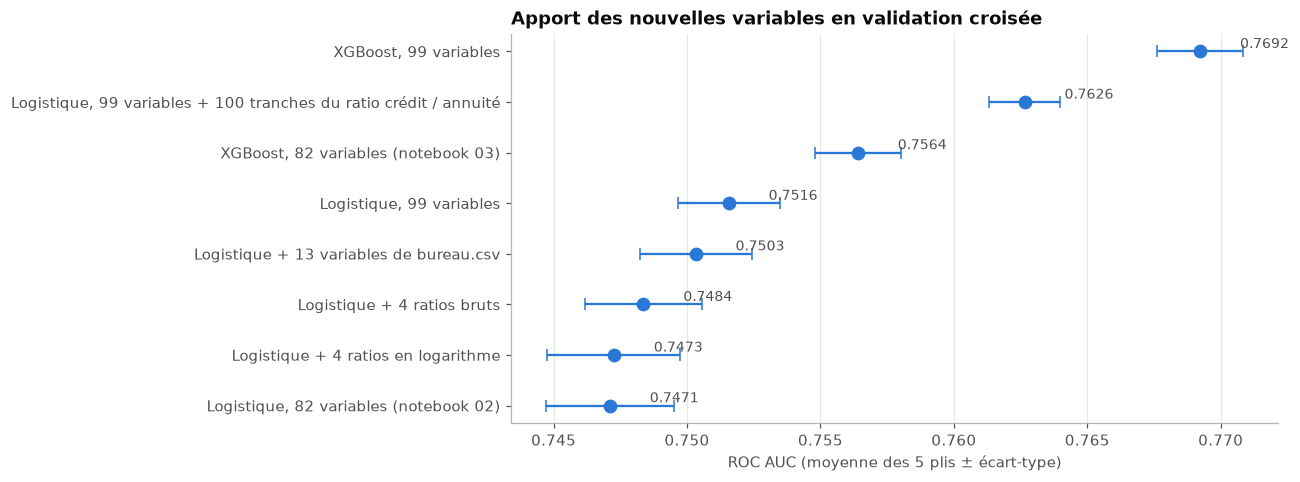

,variables,roc_auc,ecart_type,pr_auc
modele,,,,
"XGBoost, 99 variables",99,0.7692,0.0016,0.255
"Logistique, 99 variables + 100 tranches du ratio crédit / annuité",99,0.7626,0.0013,0.247
"XGBoost, 82 variables (notebook 03)",82,0.7564,0.0016,0.240
"Logistique, 99 variables",99,0.7516,0.0019,0.233
Logistique + 13 variables de bureau.csv,95,0.7503,0.0021,0.231
Logistique + 4 ratios bruts,86,0.7484,0.0022,0.229
Logistique + 4 ratios en logarithme,86,0.7473,0.0025,0.227
"Logistique, 82 variables (notebook 02)",82,0.7471,0.0024,0.227


In [12]:
comparaison = pd.DataFrame(resultats).set_index("modele").sort_values("roc_auc")

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.errorbar(comparaison["roc_auc"], comparaison.index, xerr=comparaison["ecart_type"], fmt="o", color=BLEU,
            markersize=8, capsize=4, elinewidth=1.5)
for nom, ligne in comparaison.iterrows():
    ax.text(ligne["roc_auc"] + 0.0015, nom, f"{ligne['roc_auc']:.4f}", va="bottom", color="#52514e", fontsize=9)
ax.xaxis.set_major_locator(MultipleLocator(0.005))
ax.set_xlabel("ROC AUC (moyenne des 5 plis ± écart-type)")
ax.set_title("Apport des nouvelles variables en validation croisée", loc="left")
ax.grid(axis="y", visible=False)
plt.show()

(comparaison.drop(columns="auc_par_pli").sort_values("roc_auc", ascending=False)
 .style.format({"variables": "{:,.0f}", "roc_auc": "{:.4f}", "ecart_type": "{:.4f}", "pr_auc": "{:.3f}"}))

Comme au notebook 03, on compare pli par pli, puisque tous les modèles sont évalués sur les mêmes plis :

In [13]:
par_pli = pd.DataFrame({r["modele"]: r["auc_par_pli"] for r in resultats}, index=[f"pli {k}" for k in range(1, 6)])
ecarts = pd.DataFrame({
    "logistique : 99 variables + tranches − 82": par_pli[NOM_LOGISTIQUE_INTERVALLES] - par_pli[NOM_LOGISTIQUE_82],
    "XGBoost : 99 − 82 variables": par_pli[NOM_XGB_99] - par_pli[NOM_XGB_82],
    "XGBoost 99 − logistique 99 + tranches": par_pli[NOM_XGB_99] - par_pli[NOM_LOGISTIQUE_INTERVALLES],
})
ecarts.loc["moyenne"] = ecarts.mean()
ecarts.style.format("{:+.4f}")

,logistique : 99 variables + tranches − 82,XGBoost : 99 − 82 variables,XGBoost 99 − logistique 99 + tranches
pli 1,+0.0172,+0.0125,+0.0047
pli 2,+0.0154,+0.0119,+0.0083
pli 3,+0.0124,+0.0132,+0.0056
pli 4,+0.0163,+0.0128,+0.0088
pli 5,+0.0165,+0.0136,+0.0054
moyenne,+0.0155,+0.0128,+0.0066


- **Les deux modèles progressent sur les 5 plis** : de +0,012 à +0,017 pour la logistique avec tranches, de +0,012 à +0,014 pour XGBoost.
  Le gain des nouvelles variables est net, bien au-delà des variations d'un pli à l'autre.
- **XGBoost reste devant la meilleure logistique sur les 5 plis** (+0,0066 en moyenne).
- **Sans les tranches, l'écart entre XGBoost et la logistique doublerait** : 0,7692 contre 0,7516, soit 0,018 au lieu de 0,009 au notebook 03.
  Les nouvelles variables profitent d'abord au modèle qui sait exploiter un lien en dents de scie. Les tranches comblent une partie de ce retard.

In [14]:
# Prédictions out-of-fold gardées pour la suite (déséquilibre, seuil, calibration)
pd.DataFrame({
    "SK_ID_CURR": train["SK_ID_CURR"].to_numpy(),
    "TARGET": y,
    "logistique_99": oof_logistique_99,
    "logistique_99_tranches": oof_logistique_intervalles,
    "xgboost_99": oof_xgb_99,
}).to_parquet(DOSSIER_PROCESSED / "oof_04.parquet", index=False)
print("Enregistré : data/processed/oof_04.parquet")
print(f"Durée totale du notebook : {(time.perf_counter() - DEBUT_NOTEBOOK) / 60:.0f} minutes")

Enregistré : data/processed/oof_04.parquet
Durée totale du notebook : 9 minutes


**À retenir** :

| Modèle | 82 variables | 99 variables | Gain |
|---|---|---|---|
| Régression logistique | 0,747 | 0,752 (**0,763** avec 100 tranches du ratio crédit / annuité) | +0,016 |
| **XGBoost** | 0,756 | **0,769** | +0,013 |

- **Les nouvelles variables rapportent plus que le changement d'algorithme** : +0,013 à +0,016, contre +0,009 pour le passage
  de la logistique à XGBoost au notebook 03.
- **La variable la plus utile est `RATIO_CREDIT_ANNUITE`**, presque inutile seule (AUC 0,533) parce que son lien avec le défaut est en dents de scie.
  Elle reflète probablement la grille tarifaire de Home Credit (durée et taux) : un point à signaler dans les limites du modèle.
- **Un ratio en logarithme n'apporte rien à une régression logistique qui contient déjà le logarithme de chaque montant.**
  Un arbre, lui, ne sait pas construire un ratio : il faut le lui donner.
- **Le meilleur modèle est maintenant XGBoost avec les 99 variables** (ROC AUC 0,769, PR AUC 0,255).
  Ses prédictions out-of-fold sont enregistrées dans `oof_04.parquet` pour les étapes suivantes.

**Prochaine étape** (étape 8 du README) : le déséquilibre des classes. On comparera l'absence de correction, la pondération
des défauts (`scale_pos_weight`, `class_weight`) et le sous-échantillonnage des bons clients.
Le jeu de test n'a toujours pas été utilisé.